In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    confusion_matrix, classification_report, ConfusionMatrixDisplay
)

print("Library siap digunakan.")


Library siap digunakan.


In [2]:
np.random.seed(42)
n = 1000

jumlah = np.random.randint(1, 15, n)
nilai_invoice = np.random.randint(100_000, 5_000_000, n)
jenis_pelanggan = np.random.choice(["Baru", "Lama", "Prioritas"], n, p=[0.35, 0.50, 0.15])
produk = np.random.choice(["A", "B", "C", "D"], n)

# Buat probabilitas keterlambatan yang relatif rendah
prob = np.full(n, 0.10)
prob += np.where(jenis_pelanggan == "Baru", 0.07, 0)
prob += np.where(jumlah >= 10, 0.08, 0)
prob += np.where(nilai_invoice > 3_500_000, 0.04, 0)
prob = np.clip(prob, 0.02, 0.45)

terlambat = np.random.binomial(1, prob)

df = pd.DataFrame({
    "jumlah_barang": jumlah,
    "nilai_invoice": nilai_invoice,
    "jenis_pelanggan": jenis_pelanggan,
    "produk": produk,
    "terlambat": terlambat
})

df["status_pembayaran"] = df["terlambat"].map({0: "Tepat waktu", 1: "Terlambat"})
df.head()


,jumlah_barang,nilai_invoice,jenis_pelanggan,produk,terlambat,status_pembayaran
0,7,4547794,Baru,C,1,Terlambat
1,4,1715952,Baru,A,0,Tepat waktu
2,13,1396516,Prioritas,C,0,Tepat waktu
3,11,2630179,Prioritas,A,1,Terlambat
4,8,1656617,Baru,B,0,Tepat waktu


In [3]:
print("Ukuran dataset:", df.shape)
print("\\nNilai kosong per kolom:")
print(df.isna().sum())
print("\\nJumlah baris duplikat:", df.duplicated().sum())
print("\\nTipe data:")
print(df.dtypes)
print("\\nDistribusi target:")
print(df["status_pembayaran"].value_counts())


Ukuran dataset: (1000, 6)
\nNilai kosong per kolom:
jumlah_barang        0
nilai_invoice        0
jenis_pelanggan      0
produk               0
terlambat            0
status_pembayaran    0
dtype: int64
\nJumlah baris duplikat: 0
\nTipe data:
jumlah_barang         int64
nilai_invoice         int64
jenis_pelanggan      object
produk               object
terlambat             int64
status_pembayaran    object
dtype: object
\nDistribusi target:
status_pembayaran
Tepat waktu    843
Terlambat      157
Name: count, dtype: int64


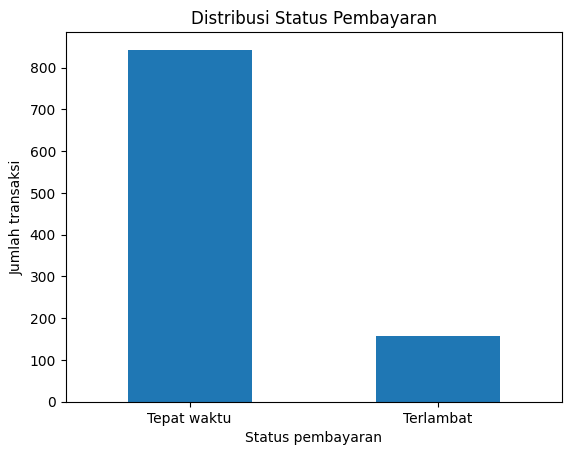

In [4]:
counts = df["status_pembayaran"].value_counts()
counts.plot(kind="bar")
plt.title("Distribusi Status Pembayaran")
plt.xlabel("Status pembayaran")
plt.ylabel("Jumlah transaksi")
plt.xticks(rotation=0)
plt.show()


In [5]:
ringkasan = df.groupby("status_pembayaran").agg(
    jumlah_transaksi=("nilai_invoice", "count"),
    rata_rata_invoice=("nilai_invoice", "mean"),
    median_invoice=("nilai_invoice", "median"),
    rata_rata_barang=("jumlah_barang", "mean")
).round(2)

ringkasan


,jumlah_transaksi,rata_rata_invoice,median_invoice,rata_rata_barang
status_pembayaran,,,,
Tepat waktu,843,2465444.77,2463999.0,7.18
Terlambat,157,2749566.37,2856944.0,8.87


In [6]:
fitur_numerik = ["jumlah_barang", "nilai_invoice"]
fitur_kategori = ["jenis_pelanggan", "produk"]
X = df[fitur_numerik + fitur_kategori]
y = df["terlambat"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

preprocessor = ColumnTransformer(transformers=[
    ("numerik", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]), fitur_numerik),
    ("kategori", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ]), fitur_kategori)
])

model = Pipeline([
    ("preparation", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000))
])

model.fit(X_train, y_train)
prediksi = model.predict(X_test)

print("Model selesai dilatih.")


Model selesai dilatih.


Akurasi: 0.844
Precision kelas terlambat: 0.000
Recall kelas terlambat: 0.000
\nLaporan klasifikasi:
              precision    recall  f1-score   support

 Tepat waktu       0.84      1.00      0.92       211
   Terlambat       0.00      0.00      0.00        39

    accuracy                           0.84       250
   macro avg       0.42      0.50      0.46       250
weighted avg       0.71      0.84      0.77       250



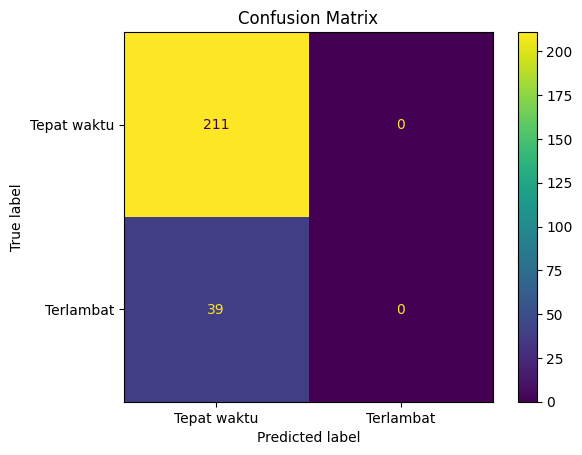

In [7]:
akurasi = accuracy_score(y_test, prediksi)
presisi = precision_score(y_test, prediksi, zero_division=0)
recall_terlambat = recall_score(y_test, prediksi, zero_division=0)

print(f"Akurasi: {akurasi:.3f}")
print(f"Precision kelas terlambat: {presisi:.3f}")
print(f"Recall kelas terlambat: {recall_terlambat:.3f}")
print("\\nLaporan klasifikasi:")
print(classification_report(
    y_test, prediksi,
    labels=[0, 1],
    target_names=["Tepat waktu", "Terlambat"],
    zero_division=0
))

ConfusionMatrixDisplay.from_predictions(
    y_test, prediksi,
    display_labels=["Tepat waktu", "Terlambat"],
    values_format="d"
)
plt.title("Confusion Matrix")
plt.show()


In [8]:
prediksi_sederhana = np.zeros_like(y_test)

print("Model selalu memprediksi tepat waktu")
print(f"Akurasi: {accuracy_score(y_test, prediksi_sederhana):.3f}")
print(f"Recall keterlambatan: {recall_score(y_test, prediksi_sederhana, zero_division=0):.3f}")
print("\\nBandingkan metrik ini dengan model Logistic Regression di atas.")


Model selalu memprediksi tepat waktu
Akurasi: 0.844
Recall keterlambatan: 0.000
\nBandingkan metrik ini dengan model Logistic Regression di atas.
